# 01 - Data cleaning and clustering
**Project:** Predicting antimicrobial peptides (AMPs) from sequence with machine learning

**Goal:** I build a clean, balanced dataset of AMPs (label 1) and non-AMPs (label 0), then group similar peptides into clusters so that my model testing is fair.

**Input:** `data/raw/general_amps.fasta` (DRAMP), `data/raw/negatives_uniprot.fasta` (UniProt)
**Output:** `data/processed/peptides_clean.csv`, `clusters.clstr`

In [1]:
import os, sys, shutil, subprocess
import pandas as pd

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("CD-HIT installed:", shutil.which("cd-hit") is not None)

for folder in ["../data/raw", "../data/processed"]:
    os.makedirs(folder, exist_ok=True)

Python: 3.11.17
pandas: 3.0.6
CD-HIT installed: True


## Part 2 - Raw data
I do not store the raw data in the GitHub repo, so anyone repeating this work has to download it again.

**Positives (known AMPs):** DRAMP, General dataset, FASTA format, from dramp.cpu-bioinfor.org > Download. Saved as `data/raw/general_amps.fasta`. Downloaded 14 Oct 2026.

**Negatives (not known to be antimicrobial):** UniProt Swiss-Prot reviewed proteins, length 10-100, excluding keywords KW-0929 (Antimicrobial) and KW-0044 (Antibiotic). Saved as `data/raw/negatives_uniprot.fasta`. Downloaded 14 Oct 2026.

**Limitation:** "not tagged antimicrobial" does not prove a peptide has no antimicrobial activity, so some of my negatives may be unlabelled AMPs.

In [2]:
for name in ["general_amps.fasta", "negatives_uniprot.fasta"]:
    path = f"../data/raw/{name}"
    assert os.path.exists(path), f"Missing {path}"
    n = sum(1 for line in open(path, encoding="utf-8", errors="replace") if line.startswith(">"))
    print(f"{name}: {n} sequences")

general_amps.fasta: 12784 sequences
negatives_uniprot.fasta: 55010 sequences


## Part 3 - Load the sequences
I use a custom reader instead of Biopython because the raw files have two quirks:
1. DRAMP contains a hidden non-ASCII character (a non-breaking space) in at least one sequence, which makes Biopython crash.
2. The UniProt download inserts a line containing only a comma after every record. Left in, it would be glued onto each sequence and make every sequence look invalid.

My reader removes both and returns one table per file with columns `id`, `seq` and `label` (1 = AMP, 0 = non-AMP).

In [3]:
def load_fasta(path, label):
    ids, seqs = [], []
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.replace("\xa0", "").replace(",", "").strip()
            if line.startswith(">"):
                parts = line[1:].split()
                ids.append(parts[0] if parts else "")
                seqs.append("")
            elif ids:
                seqs[-1] += line
    df = pd.DataFrame({"id": ids, "seq": [s.upper() for s in seqs]})
    df["label"] = label
    return df

pos = load_fasta("../data/raw/general_amps.fasta", 1)
neg = load_fasta("../data/raw/negatives_uniprot.fasta", 0)
print("Raw:", len(pos), "positives,", len(neg), "negatives")
pos.head(3)

Raw: 12784 positives, 55010 negatives


,id,seq,label
0,DRAMP00005,SLGPAIKATRQVCPKATRFVTVSCKKSDCQ,1
1,DRAMP00017,VTSWSLCTPGCTSPGGGSNCSFCC,1
2,DRAMP00032,GNGVLKTISHECNMNTWQFLFTCC,1


## Part 4 - Clean
I apply these filters to both groups:
1. Keep only sequences made of the 20 standard amino acids (this drops X, B, Z, U and other symbols).
2. Keep lengths of 10 to 50 residues, the range where most AMPs sit.
3. Remove exact duplicate sequences.

Then I remove any negative whose sequence is identical to a positive, since the same sequence cannot belong to both classes.

In [4]:
STD = set("ACDEFGHIKLMNPQRSTVWY")
MIN_LEN, MAX_LEN = 10, 50

def clean(df, name):
    n0 = len(df)
    df = df[df["seq"].apply(lambda s: set(s) <= STD)]
    n1 = len(df)
    df = df[df["seq"].str.len().between(MIN_LEN, MAX_LEN)]
    n2 = len(df)
    df = df.drop_duplicates("seq")
    print(f"{name}: {n0} raw -> {n1} standard residues -> {n2} length {MIN_LEN}-{MAX_LEN} -> {len(df)} unique")
    return df

pos = clean(pos, "Positives")
neg = clean(neg, "Negatives")

overlap = set(pos["seq"]) & set(neg["seq"])
neg = neg[~neg["seq"].isin(overlap)]
print("Negatives removed because identical to a positive:", len(overlap))

Positives: 12784 raw -> 10956 standard residues -> 8737 length 10-50 -> 8195 unique
Negatives: 55010 raw -> 54265 standard residues -> 10737 length 10-50 -> 7886 unique
Negatives removed because identical to a positive: 240


## Part 5 - Check the cleaned data
After cleaning, I have 8195 positives (AMPs) and 7646 negatives (non-AMPs).
Before clustering, I compare sequence lengths between the two classes. If the lengths differ strongly, a model could learn length instead of real antimicrobial features, so I check this first.

Final: 8195 positives, 7646 negatives
Shared sequences left: 0

Median length  - positives: 20.0 | negatives: 35.0
Mean length    - positives: 22.9 | negatives: 32.2


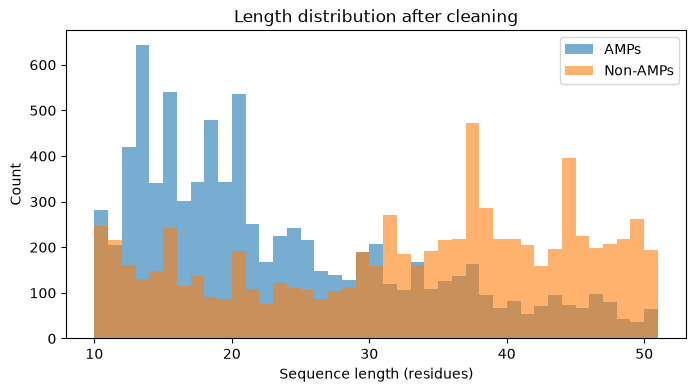

In [5]:
import matplotlib.pyplot as plt

print("Final:", len(pos), "positives,", len(neg), "negatives")
print("Shared sequences left:", len(set(pos["seq"]) & set(neg["seq"])))
print()
print("Median length  - positives:", pos["seq"].str.len().median(),
      "| negatives:", neg["seq"].str.len().median())
print("Mean length    - positives:", round(pos["seq"].str.len().mean(), 1),
      "| negatives:", round(neg["seq"].str.len().mean(), 1))

plt.figure(figsize=(8, 4))
plt.hist(pos["seq"].str.len(), bins=range(10, 52), alpha=0.6, label="AMPs")
plt.hist(neg["seq"].str.len(), bins=range(10, 52), alpha=0.6, label="Non-AMPs")
plt.xlabel("Sequence length (residues)")
plt.ylabel("Count")
plt.legend()
plt.title("Length distribution after cleaning")
plt.show()

## Part 6 - Match the lengths of the two classes
The check in Part 5 shows a clear length bias: AMPs have a median length of 20 and non-AMPs 35. A model could learn "short = AMP" instead of real antimicrobial features.

To remove this, I go through each length from 10 to 50 and keep the same number of peptides from both classes, using the smaller of the two counts and sampling at random (fixed seed, so the result is reproducible). The two classes then have an identical length distribution and are perfectly balanced.

The cost is a smaller dataset, because some lengths have far more AMPs than non-AMPs. I keep the full cleaned tables as `pos_full` and `neg_full` in case I need them later.

Before matching: 8195 positives, 7646 negatives
After matching:  4779 positives, 4779 negatives
Median length  - positives: 27.0 | negatives: 27.0
Mean length    - positives: 26.7 | negatives: 26.7


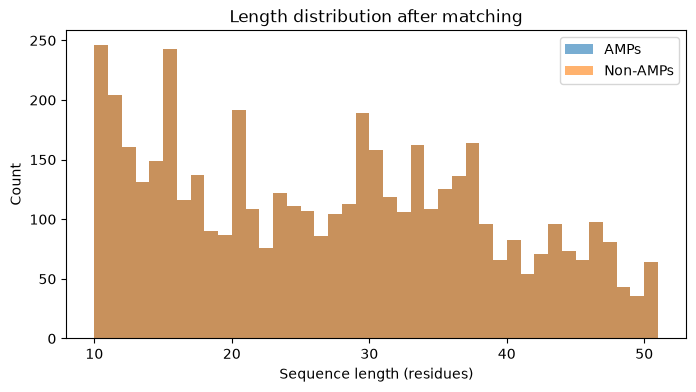

In [6]:
pos_full, neg_full = pos.copy(), neg.copy()
pos_full["length"] = pos_full["seq"].str.len()
neg_full["length"] = neg_full["seq"].str.len()

keep_pos, keep_neg = [], []
for L in range(MIN_LEN, MAX_LEN + 1):
    p = pos_full[pos_full["length"] == L]
    n = neg_full[neg_full["length"] == L]
    k = min(len(p), len(n))
    keep_pos.append(p.sample(k, random_state=42))
    keep_neg.append(n.sample(k, random_state=42))

pos = pd.concat(keep_pos).reset_index(drop=True)
neg = pd.concat(keep_neg).reset_index(drop=True)

print("Before matching:", len(pos_full), "positives,", len(neg_full), "negatives")
print("After matching: ", len(pos), "positives,", len(neg), "negatives")
print("Median length  - positives:", pos["length"].median(), "| negatives:", neg["length"].median())
print("Mean length    - positives:", round(pos["length"].mean(), 1), "| negatives:", round(neg["length"].mean(), 1))

plt.figure(figsize=(8, 4))
plt.hist(pos["length"], bins=range(10, 52), alpha=0.6, label="AMPs")
plt.hist(neg["length"], bins=range(10, 52), alpha=0.6, label="Non-AMPs")
plt.xlabel("Sequence length (residues)")
plt.ylabel("Count")
plt.legend()
plt.title("Length distribution after matching")
plt.show()

## Part 7 - Cluster similar peptides with CD-HIT
Similar peptides in both the training and test sets would make my model look better than it really is, because it would only be recognising sequences it has already seen. To prevent this, I group similar peptides into clusters and later keep each cluster entirely on one side of the split.

I cluster all 9558 peptides (AMPs and non-AMPs together) with CD-HIT at 40% sequence identity (`-c 0.4`, word size `-n 2`, the smallest word size CD-HIT allows at this threshold). By default CD-HIT discards sequences of 10 residues or shorter, which would silently remove my length-10 peptides, so I lower this cutoff with `-l 5`. Each peptide gets a unique ID (`s0`, `s1`, ...) so that the original database IDs cannot clash. The CD-HIT output is saved in `data/processed/`.

In [9]:
all_df = pd.concat([pos, neg], ignore_index=True)
all_df["uid"] = "s" + all_df.index.astype(str)

fasta_in = "../data/processed/all_peptides.fasta"
with open(fasta_in, "w") as f:
    for uid, seq in zip(all_df["uid"], all_df["seq"]):
        f.write(f">{uid}\n{seq}\n")

out_prefix = "../data/processed/clusters"
result = subprocess.run(
    ["cd-hit", "-i", fasta_in, "-o", out_prefix,
     "-c", "0.4", "-n", "2", "-l", "5", "-d", "0", "-M", "0", "-T", "0"],
    capture_output=True, text=True
)

print("Return code:", result.returncode)
print("\n".join(result.stdout.strip().splitlines()[-6:]))
print(result.stderr[-500:])

Return code: 0
Approximated maximum memory consumption: 66M
writing new database
writing clustering information
program completed !

Total CPU time 17.20



## Part 8 - Add cluster numbers and save the clean dataset
CD-HIT wrote its results to `clusters.clstr`. I read that file and give every peptide a cluster number.

I then check how big the clusters are and how many of them contain both AMPs and non-AMPs. Mixed clusters are useful, because they show that the two classes are not separated just by sequence similarity.

Finally I save the full table (`uid`, `id`, `seq`, `label`, `length`, `cluster`) as `data/processed/peptides_clean.csv`. This is the dataset I use for the model.

In [10]:
import re

cluster_of = {}
current = None
with open("../data/processed/clusters.clstr") as f:
    for line in f:
        if line.startswith(">Cluster"):
            current = int(line.split()[1])
        else:
            uid = re.search(r">(s\d+)\.\.\.", line).group(1)
            cluster_of[uid] = current

all_df["cluster"] = all_df["uid"].map(cluster_of)
missing = all_df["cluster"].isna().sum()
print("Peptides without a cluster:", missing)
assert missing == 0, "Some peptides have no cluster"
all_df["cluster"] = all_df["cluster"].astype(int)

sizes = all_df.groupby("cluster").size()
mixed = (all_df.groupby("cluster")["label"].nunique() == 2).sum()

print("Peptides:", len(all_df))
print("Clusters:", len(sizes))
print("Singleton clusters (1 peptide):", (sizes == 1).sum())
print("Largest cluster:", sizes.max(), "peptides")
print("Median cluster size:", sizes.median())
print("Clusters containing both AMPs and non-AMPs:", mixed)

all_df = all_df[["uid", "id", "seq", "label", "length", "cluster"]]
all_df.to_csv("../data/processed/peptides_clean.csv", index=False)
print("Saved: ../data/processed/peptides_clean.csv")
all_df.head()

Peptides without a cluster: 0
Peptides: 9558
Clusters: 1450
Singleton clusters (1 peptide): 577
Largest cluster: 142 peptides
Median cluster size: 2.0
Clusters containing both AMPs and non-AMPs: 549
Saved: ../data/processed/peptides_clean.csv


,uid,id,seq,label,length,cluster
0,s0,DRAMP29098,GLSRLFTALK,1,10,16
1,s1,DRAMP30027,EEQAKTFLDK,1,10,102
2,s2,DRAMP32992,LKKLKFLKKQ,1,10,26
3,s3,DRAMP31465,FFVIFYRRKK,1,10,42
4,s4,DRAMP35956,FHAVPQSFYT,1,10,4


## Part 9 - Split into training and test sets by cluster
I split the data 80% / 20% using whole clusters, not individual peptides. All peptides from one cluster go to the same side, so the test set contains no close relatives of the training peptides, and my test score will show how well the model handles new sequences.

I use a fixed random seed (42) so the split can be reproduced. The size of each side and the class balance are not exactly 80/20 and 50/50, because clusters are different sizes and move as a block. I check that no cluster appears in both sets, and I save the two tables as `train.csv` and `test.csv` in `data/processed/`.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv("../data/processed/peptides_clean.csv")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, df["label"], groups=df["cluster"]))
train, test = df.iloc[train_idx], df.iloc[test_idx]

shared = set(train["cluster"]) & set(test["cluster"])
print("Train:", len(train), "peptides |", train["cluster"].nunique(), "clusters")
print("Test: ", len(test), "peptides |", test["cluster"].nunique(), "clusters")
print("Clusters in both sets:", len(shared))
print()
print("Train labels (1 = AMP, 0 = non-AMP):", train["label"].value_counts().to_dict())
print("Test labels  (1 = AMP, 0 = non-AMP):", test["label"].value_counts().to_dict())
print("Median length - train:", train["length"].median(), "| test:", test["length"].median())
assert len(shared) == 0, "A cluster appears in both sets"

train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)
print("Saved: train.csv and test.csv")

Train: 7688 peptides | 1160 clusters
Test:  1870 peptides | 290 clusters
Clusters in both sets: 0

Train labels (1 = AMP, 0 = non-AMP): {0: 3848, 1: 3840}
Test labels  (1 = AMP, 0 = non-AMP): {1: 939, 0: 931}
Median length - train: 26.0 | test: 29.0
Saved: train.csv and test.csv


## Summary
Starting from 12784 AMPs (DRAMP) and 55010 non-AMPs (UniProt), I cleaned both groups to standard amino acids, lengths of 10 to 50 residues and no duplicates, and removed 240 negatives that were identical to a positive. Because AMPs were much shorter than non-AMPs (median 20 vs 35), I matched the two classes length by length, which left 4779 AMPs and 4779 non-AMPs.

I clustered the 9558 peptides at 40% identity with CD-HIT, giving 1450 clusters (largest: 142 peptides), and split them 80/20 by whole cluster:

- `train.csv`: 7688 peptides (3848 non-AMPs, 3840 AMPs)
- `test.csv`: 1870 peptides (939 AMPs, 931 non-AMPs)
- no cluster is shared between the two sets
